# Real-Time Credit Card Fraud Detection
### Imbalanced learning · Geo-velocity feature engineering · Cost-based thresholding · SHAP explainability

**Problem.** Card fraud is rare (well under 1% of transactions), costly when missed, and costly to over-flag
(every false alarm means analyst time and an annoyed customer). This notebook builds an end-to-end fraud
detection pipeline that goes beyond "fit a classifier and report accuracy".

**What this notebook demonstrates**

| Step | Skill shown |
|---|---|
| 1. Synthetic data generator | Realistic simulation incl. legitimate travel (hard negatives) and **concept drift** |
| 2. EDA | Working with extreme class imbalance |
| 3. Feature engineering | Geo-velocity (haversine, implied speed), behavioural baselines, velocity counts, all leakage-free |
| 4. Imbalance strategies + model comparison | Class weights vs. under-sampling vs. SMOTE; LR / RF / LightGBM / Isolation Forest |
| 5. Time-based validation | Train → validation → test split by date, never random |
| 6. Cost-sensitive threshold | Optimising **dollars**, not F1 |
| 7. Concept drift | Measuring model decay and the benefit of retraining |
| 8. SHAP explanations | Human-readable reason codes for every alert |
| 9. Business impact | Translating ML metrics into money |

---
## Results at a glance

*Seed 42, 108K transactions, ~0.66% fraud. Test = final 30 days, which include a shift in fraud tactics.*

| Finding | Result |
|---|---|
| **Best models** | LightGBM and Random Forest tie at **0.56 test PR-AUC** (random baseline: 0.0065, an ~85x lift); **0.94 PR-AUC** on the pre-drift week |
| **Supervised vs. unsupervised** | Isolation Forest (no labels) reaches 0.22 PR-AUC, so labels are worth roughly 2.5x |
| **Imbalance handling** | Class weights / under-sampling / no resampling are within noise on validation; SMOTE was slightly worse |
| **Cost-optimal threshold** | Cuts total fraud cost by **58%** vs. no model ($22.2K → $9.4K over 30 days). The F1-optimal threshold only achieves 42%, because it ignores that missed fraud costs far more than a false alarm |
| **Concept drift** | PR-AUC falls from **0.94 to ~0.36-0.47** once fraudsters change tactics; weekly retraining recovers part of it (+0.11 PR-AUC in the last week) but doesn't fully close the gap |
| **Explainability** | Every alert comes with plain-English reason codes (e.g. *"3,361 km from the customer's usual location"*, *"implied travel speed of 251 km/h"*) |

## Load Packages and General setup

In [65]:
# Uncomment to install dependencies
# !pip install numpy pandas scikit-learn lightgbm shap imbalanced-learn matplotlib seaborn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
from IPython.display import display, Markdown

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)

## 1. Data: a synthetic transaction simulator

Public fraud datasets such as Kaggle Credit Fraud Dataset are either anonymised (PCA features, no location) or lack the time/location
structure needed for geo-velocity features. So I simulate a card portfolio:

**Legitimate behaviour**
- Each customer has a home city, a typical spend level, favourite merchant categories and a daily rhythm.
- ~50% of customers take **legitimate trips** to other cities, ~10% are **night owls**, and ~4% of purchases are
  unusually large. These create "far from home", "at 2am" and "big amount" transactions that are *not* fraud,
  which makes the problem realistic.

**Fraud patterns** (a compromised card is used in one of these ways)

| Pattern | Description |
|---|---|
| **A: Geo-hop** | Purchase in a far-away city 1-6 h after a legit local purchase (the "impossible travel" case) |
| **B: Night spree** | Several larger-than-usual purchases between 00:00 and 05:00 (sometimes locally) |
| **C: Card testing** | Burst of tiny online purchases within minutes (far away or local) |
| **D: Low-and-slow** | Moderate, daytime, *local* purchases. Rare before day 70, dominant after, to simulate **concept drift** |

The `fraud_type` column is used only for analysis. It is never a model feature.

In [66]:
CITIES = {
    "Toronto": (43.65, -79.38), "Montreal": (45.50, -73.57), "Ottawa": (45.42, -75.70),
    "Vancouver": (49.28, -123.12), "Calgary": (51.05, -114.07), "Winnipeg": (49.90, -97.14),
    "Halifax": (44.65, -63.58), "New York": (40.71, -74.01), "Chicago": (41.88, -87.63),
    "Los Angeles": (34.05, -118.24),
}
CITY_NAMES = list(CITIES)
CITY_W = np.array([.28, .14, .08, .12, .09, .05, .04, .08, .07, .05]); CITY_W /= CITY_W.sum()

CATS = ["grocery", "restaurant", "fuel", "retail", "travel", "electronics",
        "entertainment", "online_services", "health", "utilities"]
CAT_MULT = np.array([1.5, 1.0, 1.3, 2.0, 8.0, 4.0, 0.8, 0.5, 1.5, 3.0])  # typical spend multiplier

N_CUST, N_DAYS, DRIFT_DAY, N_FRAUD_EVENTS = 1500, 90, 70, 170
START = pd.Timestamp("2025-01-01")

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

# pre-compute which cities are "far" (>500 km) from each home city
FAR = {a: [b for b in CITY_NAMES if haversine_km(*CITIES[a], *CITIES[b]) > 500] for a in CITY_NAMES}

In [67]:
def generate_transactions(seed=SEED):
    rng = np.random.default_rng(seed)
    legit_frames, customers, cust_secs = [], [], []

    # ---------- legitimate activity ----------
    for cid in range(N_CUST):
        home = rng.choice(CITY_NAMES, p=CITY_W)
        scale = rng.lognormal(np.log(30), 0.35)
        cat_p = rng.dirichlet(np.ones(len(CATS)) * 2)
        rate = rng.uniform(0.4, 1.2)
        peak = rng.normal(23, 1.5) if rng.random() < 0.10 else rng.normal(15, 2.5)   # 10% night owls
        customers.append(dict(home=home, scale=scale))

        n = rng.poisson(rate * N_DAYS)
        secs = np.sort(rng.integers(0, N_DAYS, n) * 86400 + (rng.normal(peak, 4, n) % 24) * 3600)
        lat0, lon0 = CITIES[home]
        lat = lat0 + rng.normal(0, 0.05, n)
        lon = lon0 + rng.normal(0, 0.07, n)

        for _ in range(rng.choice([0, 1, 2], p=[.5, .35, .15])):   # legitimate trips (0-2 per customer)
            tcity = rng.choice([c for c in CITY_NAMES if c != home])
            t0 = rng.uniform(3, N_DAYS - 8); t1 = t0 + rng.uniform(1, 6)
            m = (secs >= t0 * 86400) & (secs < t1 * 86400)
            lat[m] = CITIES[tcity][0] + rng.normal(0, 0.05, m.sum())
            lon[m] = CITIES[tcity][1] + rng.normal(0, 0.07, m.sum())

        cat_idx = rng.choice(len(CATS), n, p=cat_p)
        amt = rng.lognormal(np.log(scale * CAT_MULT[cat_idx]), 0.55)
        big = rng.random(n) < 0.04                                 # occasional large legitimate purchases
        amt[big] *= rng.uniform(3, 7, big.sum())
        legit_frames.append(pd.DataFrame(dict(customer_id=cid, secs=secs, amount=amt,
                                              category=np.array(CATS)[cat_idx], lat=lat, lon=lon,
                                              is_fraud=0, fraud_type="none")))
        cust_secs.append(secs)

    # ---------- fraud events ----------
    fraud_frames = []
    for _ in range(N_FRAUD_EVENTS):
        cid = rng.integers(N_CUST); c = customers[cid]; home, scale = c["home"], c["scale"]
        day = rng.uniform(1, N_DAYS - 1)
        if rng.random() < (0.05 if day < DRIFT_DAY else 0.60):
            ftype = "D_low_and_slow"
        else:
            ftype = rng.choice(["A_geo_hop", "B_night_spree", "C_card_testing"], p=[.4, .3, .3])
        far_city = rng.choice(FAR[home])

        if ftype == "A_geo_hop":
            cs = cust_secs[cid]
            if len(cs) == 0: continue
            anchor = cs[min(np.searchsorted(cs, day * 86400), len(cs) - 1)]
            k = rng.integers(1, 5)
            times = anchor + rng.uniform(1, 6) * 3600 + np.cumsum(rng.uniform(5, 40, k) * 60)
            cat_idx = rng.choice([0, 1, 3, 4, 5], k)
            amt = scale * CAT_MULT[cat_idx] * rng.uniform(0.8, 2.5, k)
            city = far_city
        elif ftype == "B_night_spree":
            k = rng.integers(3, 9)
            times = int(day) * 86400 + rng.uniform(0, 5) * 3600 + np.cumsum(rng.uniform(2, 25, k) * 60)
            cat_idx = rng.choice([1, 3, 4, 5, 7], k)
            amt = scale * rng.uniform(2, 7, k)
            city = far_city if rng.random() < 0.7 else home
        elif ftype == "C_card_testing":
            k = rng.integers(3, 8)
            times = day * 86400 + np.cumsum(rng.uniform(0.3, 2, k) * 60)
            cat_idx = np.full(k, 7)
            amt = rng.uniform(1, 8, k)
            city = far_city if rng.random() < 0.5 else home
        else:  # D_low_and_slow: looks local and fairly ordinary
            k = rng.integers(3, 7)
            times = int(day) * 86400 + rng.uniform(9, 19) * 3600 + np.cumsum(rng.uniform(20, 120, k) * 60)
            cat_idx = rng.choice([0, 1, 2, 3], k)
            amt = scale * CAT_MULT[cat_idx] * rng.uniform(1.4, 2.5, k)
            city = home

        times = np.minimum(times, N_DAYS * 86400 - 1)
        fraud_frames.append(pd.DataFrame(dict(
            customer_id=cid, secs=times, amount=amt, category=np.array(CATS)[cat_idx],
            lat=CITIES[city][0] + rng.normal(0, 0.05, k), lon=CITIES[city][1] + rng.normal(0, 0.07, k),
            is_fraud=1, fraud_type=ftype)))

    df = pd.concat(legit_frames + fraud_frames, ignore_index=True)
    df["secs"] = df["secs"].round()
    df["ts"] = START + pd.to_timedelta(df["secs"], unit="s")
    df = df.sort_values("ts").reset_index(drop=True)
    df.insert(0, "txn_id", np.arange(len(df)))
    df["amount"] = df["amount"].round(2)
    return df

raw = generate_transactions()
print(f"{len(raw):,} transactions | {raw.customer_id.nunique():,} customers | "
      f"{raw.ts.min():%Y-%m-%d} to {raw.ts.max():%Y-%m-%d}")
print(f"Fraud: {raw.is_fraud.sum():,} transactions ({raw.is_fraud.mean():.2%})")
raw.head()

108,310 transactions | 1,500 customers | 2025-01-01 to 2025-03-31
Fraud: 710 transactions (0.66%)


,txn_id,customer_id,secs,amount,category,lat,lon,is_fraud,fraud_type,ts
0,0,1062,796.000,168.470,utilities,43.683,-79.384,0,none,2025-01-01 00:13:16
1,1,684,981.000,101.080,fuel,43.593,-79.435,0,none,2025-01-01 00:16:21
2,2,359,"1,324.000",13.300,grocery,43.600,-79.233,0,none,2025-01-01 00:22:04
3,3,1094,"1,455.000",106.640,retail,51.011,-114.128,0,none,2025-01-01 00:24:15
4,4,964,"1,558.000",50.400,retail,45.484,-73.597,0,none,2025-01-01 00:25:58


## 2. Exploratory data analysis

Key point: with ~0.5% fraud, a model that predicts "legitimate" for everything scores >99% accuracy
while catching **zero** fraud. Accuracy is useless here, so I use **PR-AUC** (average precision),
**recall at fixed precision**, and dollar cost.

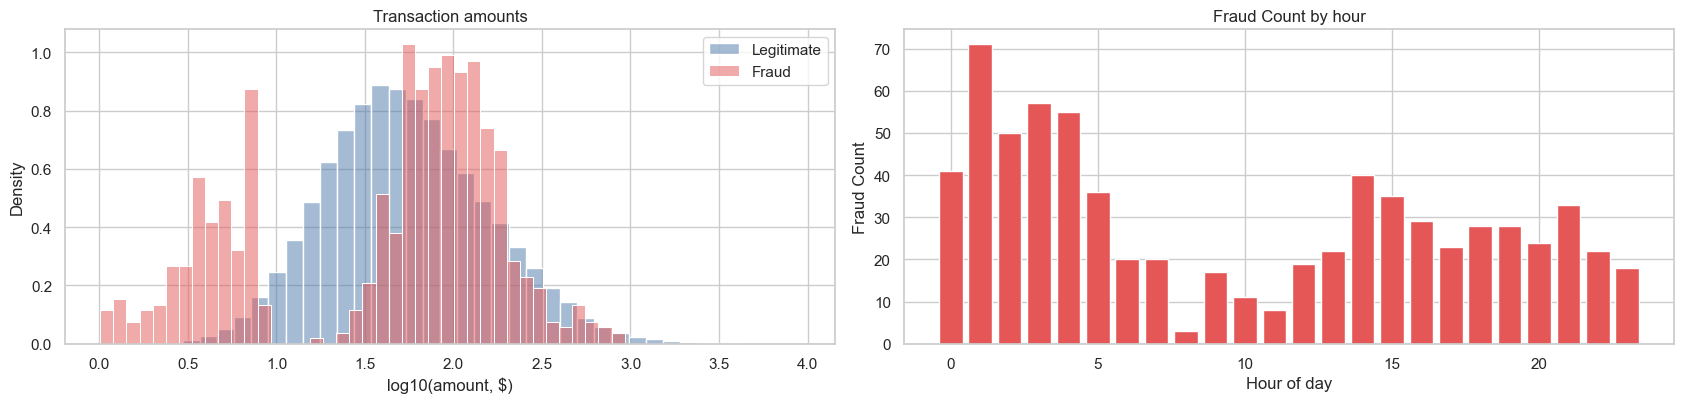

Fraud pattern type:


,transactions
fraud_type,
C_card_testing,207
B_night_spree,207
A_geo_hop,164
D_low_and_slow,132


Fraud pattern category:


,transactions
category,
online_services,255
restaurant,114
retail,101
travel,79
grocery,75
electronics,57
fuel,29


Fraud Pattern by Customer ID with at least 2 fraud transactions


,transactions
customer_id,
793,10
1142,8
1417,8
1460,8
484,8
...,...
968,2
747,2
1353,2


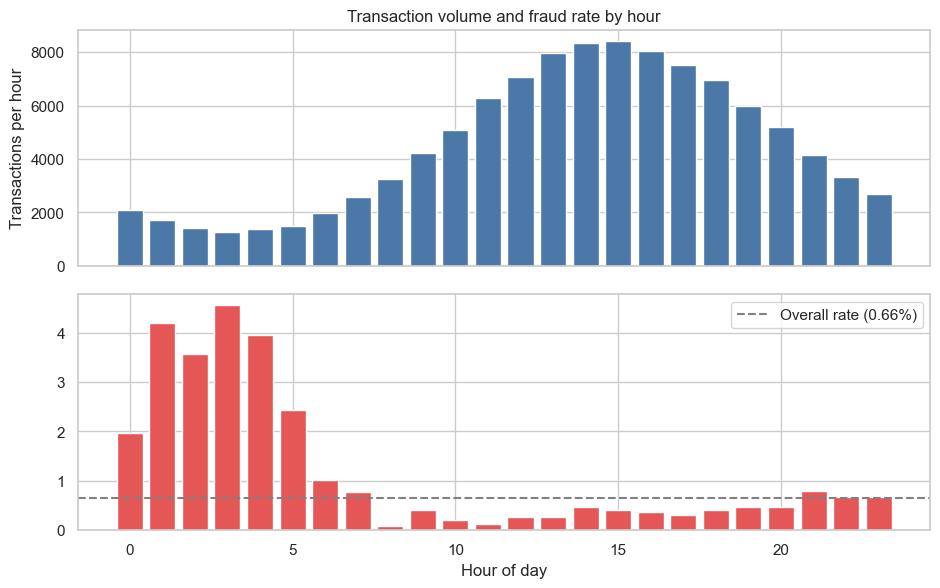

,transactions,frauds,fraud_rate_%
ts,,,
3,1253,57,4.549
1,1697,71,4.184
4,1389,55,3.960
2,1405,50,3.559
5,1476,36,2.439
0,2093,41,1.959
6,1979,20,1.011
21,4148,33,0.796


Median amount: legit $50.83 | fraud $67.29


In [68]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.2))

for lab, color in [(0, "#4C78A8"), (1, "#E45756")]:
    sns.histplot(np.log10(raw.loc[raw.is_fraud == lab, "amount"]), stat="density", bins=40,
                 color=color, alpha=.5, label="Fraud" if lab else "Legitimate", ax=ax[0])
ax[0].set_xlabel("log10(amount, $)"); ax[0].set_title("Transaction amounts"); ax[0].legend()

hour = raw.ts.dt.hour
fr = raw.groupby(hour).is_fraud.sum()
ax[1].bar(fr.index, fr.values, color="#E45756"); ax[1].set_xlabel("Hour of day")
ax[1].set_ylabel("Fraud Count"); ax[1].set_title("Fraud Count by hour")
plt.tight_layout(); plt.show()

print("Fraud pattern type:")
display(raw[raw.is_fraud == 1].fraud_type.value_counts().to_frame("transactions"))

print("Fraud pattern category:")
display(raw[raw.is_fraud == 1].category.value_counts().to_frame("transactions"))

print("Fraud Pattern by Customer ID with at least 2 fraud transactions")
#display(raw[raw.is_fraud == 1].customer_id.value_counts().to_frame("transactions"))
display(raw[raw.is_fraud == 1].customer_id.value_counts().to_frame("transactions").query("transactions >= 2"))

# Fraud rate vs. transaction volume per hour
hour_idx = raw.ts.dt.hour
hourly = raw.groupby(hour_idx).agg(transactions=("is_fraud", "size"), frauds=("is_fraud", "sum"))
hourly["fraud_rate_%"] = hourly.frauds / hourly.transactions * 100
overall_rate = raw.is_fraud.mean() * 100

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                       gridspec_kw={"height_ratios": [1, 1], "hspace": 0.12})

# Top: total volume per hour
ax[0].bar(hourly.index, hourly.transactions, color="#4C78A8")
ax[0].set_ylabel("Transactions per hour")
ax[0].set_title("Transaction volume and fraud rate by hour")

# Bottom: fraud rate per hour, with the overall rate as a reference line
fr = raw.groupby(hour_idx).is_fraud.mean() * 100
ax[1].bar(fr.index, fr.values, color="#E45756"); ax[1].set_xlabel("Hour of day")
ax[1].axhline(overall_rate, ls="--", c="grey", label=f"Overall rate ({overall_rate:.2f}%)")
ax[1].legend()

plt.show()

# Hours with unusually high fraud rates, and how much volume backs them up
display(hourly.sort_values("fraud_rate_%", ascending=False).head(8))

print(f"Median amount: legit ${raw.loc[raw.is_fraud == 0, 'amount'].median():,.2f} | fraud ${raw.loc[raw.is_fraud == 1, 'amount'].median():,.2f}")

## Transaction Amounts plot

 A lot of fraudulent transactions occur at low `amount` values. The idea is that small `Amount` transactions are less likely to get flagged as fraud by people using their credit cards and won't be flagged as fraud by banks.

## Fraud over time plot

This plot shows how many frauds occurred in each hour of the dataset's 24-hour window.

A huge number of frauds in the late hours between 1 am and 5 am.

**1. Fraud is bursty, not steady.** The counts jump high in the night hours. A single hour accounts for roughly 9% of frauds in the dataset. This is how fraud works, since a compromised card or card number gets used many times in a short window. It's also why the chronological split matters: a random split would put some transactions from a burst in training and others in test, which flatters the model.

**2. Fraud volume isn't uniform over time.** There's a busy amount of fraud in early hours, a quiet stretch around hours 8 to 11 am (8 am with almost no fraud), and a second rise from about 2 pm to 11 pm .

**3. Individual bars are noisy.** With only a few hundred frauds in total, the per-hour counts fluctuate a lot. 

## Fraud pattern type:
Card testing and night spree are most common. Night spree makes sense given fraud happens between 12 am and 5 am.

## Fraud Pattern Category
Online services have the most fraudulent transactions. This makes sense in our digital age.

## Fraud Pattern by Customer ID with at least 2 fraud transactions
151 customers had at least 2 fraudulent transactions in a given year. One customer ID 793 had 10! Quite a few had 8. These are likely from a card testing type of fraud where the agent tried the card multiple times.

## Transaction volume and fraud rate by hour

Transaction volume follows a clear ~24-hour cycle, with two overnight troughs. Fraud *rate* is
highest in those low-volume hours (up to ~4% vs. 0.66% overall) and lowest during busy daytime hours, so raw
fraud counts alone are misleading.

## 3. Feature engineering

Raw fields (amount, time, lat/lon) carry little signal on their own. The power is in **comparing each
transaction to the customer's own history**. Every feature below is computed using **only past
transactions** (`shift(1)`, backward-looking windows), so there's no look-ahead leakage and the same
code could run in a real-time scoring service.

| Feature | Captures |
|---|---|
| `dist_prev_km`, `hours_since_prev`, **`speed_kmh`** | Geo-velocity: haversine distance and implied travel speed from the previous transaction |
| `dist_home_km` | Distance from the customer's usual location (expanding median of past locations) |
| `amt_ratio` | Amount relative to the customer's rolling average of their last 20 purchases |
| `txn_count_1h`, `txn_count_24h` | Velocity: bursts of activity (card testing) |
| `new_category` | First time the customer buys in this merchant category |
| `hour`, `dow`, `is_night`, `log_amount`, category dummies | Context |

In [69]:
def engineer_features(raw):
    df = raw.sort_values(["customer_id", "ts"]).reset_index(drop=True)
    g = df.groupby("customer_id")

    # --- time / amount basics
    df["hour"] = df.ts.dt.hour + df.ts.dt.minute / 60
    df["dow"] = df.ts.dt.dayofweek
    df["is_night"] = (df.hour < 6).astype(int)
    df["log_amount"] = np.log1p(df.amount)

    # --- geo-velocity vs. previous transaction
    df["dist_prev_km"] = haversine_km(g.lat.shift(1), g.lon.shift(1), df.lat, df.lon).fillna(0)
    df["hours_since_prev"] = ((df.ts - g.ts.shift(1)).dt.total_seconds() / 3600).fillna(168).clip(upper=168)
    df["speed_kmh"] = (df.dist_prev_km / df.hours_since_prev.clip(lower=0.05)).clip(upper=3000)

    # --- distance from usual location (past-only expanding median)
    home_lat = g.lat.transform(lambda s: s.shift(1).expanding(min_periods=3).median()).fillna(df.lat)
    home_lon = g.lon.transform(lambda s: s.shift(1).expanding(min_periods=3).median()).fillna(df.lon)
    df["dist_home_km"] = haversine_km(home_lat, home_lon, df.lat, df.lon)

    # --- amount relative to customer's recent behaviour
    prev_mean = g.amount.transform(lambda s: s.shift(1).rolling(20, min_periods=3).mean())
    df["amt_ratio"] = (df.amount / prev_mean).fillna(1.0).clip(upper=50)

    # --- velocity counts (number of earlier transactions in the last 1h / 24h)
    t = (df.ts - START).dt.total_seconds().to_numpy()
    c1, c24 = np.zeros(len(df)), np.zeros(len(df))
    for _, idx in df.groupby("customer_id").indices.items():
        tt = t[idx]; pos = np.arange(len(tt))
        c1[idx] = pos - np.searchsorted(tt, tt - 3600, side="left")
        c24[idx] = pos - np.searchsorted(tt, tt - 86400, side="left")
    df["txn_count_1h"], df["txn_count_24h"] = c1, c24

    # --- first purchase in category
    df["new_category"] = (df.groupby(["customer_id", "category"]).cumcount() == 0).astype(int)

    df["day"] = (df.ts - START).dt.days
    return df

df = engineer_features(raw)
cat_dummies = pd.get_dummies(df.category, prefix="cat", dtype=int)
NUM_FEATURES = ["log_amount", "hour", "dow", "is_night", "dist_prev_km", "hours_since_prev", "speed_kmh",
                "dist_home_km", "amt_ratio", "txn_count_1h", "txn_count_24h", "new_category"]
FEATURES = NUM_FEATURES + list(cat_dummies.columns)
X = pd.concat([df[NUM_FEATURES], cat_dummies], axis=1)
y = df.is_fraud.values
print(f"{X.shape[1]} features | NaNs: {int(X.isna().sum().sum())}")
df[["customer_id", "ts", "amount", "category", "dist_prev_km", "hours_since_prev", "speed_kmh",
    "amt_ratio", "is_fraud"]].query("is_fraud == 1").head()

22 features | NaNs: 0


,customer_id,ts,amount,category,dist_prev_km,hours_since_prev,speed_kmh,amt_ratio,is_fraud
473,6,2025-01-05 01:33:16,4.130,online_services,0.000,168.000,0.000,1.000,1
474,6,2025-01-05 01:34:01,7.990,online_services,13.210,0.013,264.195,1.000,1
475,6,2025-01-05 01:34:39,3.490,online_services,6.768,0.011,135.359,1.000,1
476,6,2025-01-05 01:35:32,6.970,online_services,8.219,0.015,164.389,1.340,1
477,6,2025-01-05 01:36:11,4.220,online_services,13.590,0.011,271.803,0.748,1


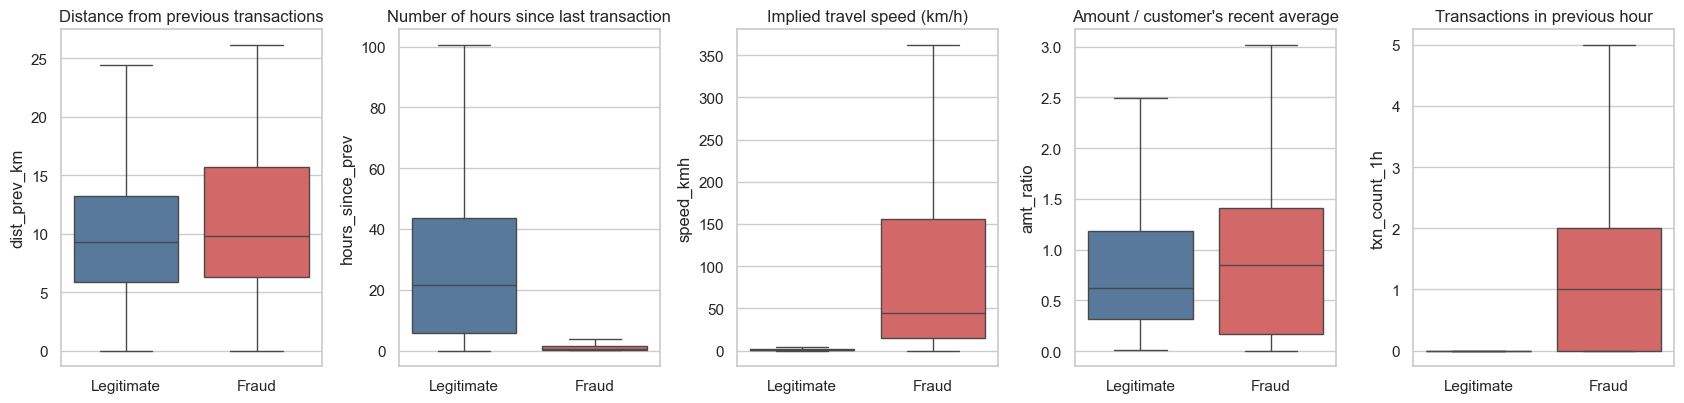

In [70]:
fig, ax = plt.subplots(1, 5, figsize=(17, 4.2))
lab = df.is_fraud.map({0: "Legitimate", 1: "Fraud"})
pal = {"Legitimate": "#4C78A8", "Fraud": "#E45756"}
for a, col, title in zip(ax, ["dist_prev_km", "hours_since_prev", "speed_kmh", "amt_ratio", "txn_count_1h"],
                         ["Distance from previous transactions", "Number of hours since last transaction", "Implied travel speed (km/h)",
                          "Amount / customer's recent average", "Transactions in previous hour"]):
    sns.boxplot(x=lab, y=df[col], palette=pal, ax=a, showfliers=False, order=["Legitimate", "Fraud"])
    a.set_title(title); a.set_xlabel("")
plt.tight_layout(); plt.show()

## Distance from previous transactions
Slightly farther distance from previous transaction when fraud but not much different.

## Number of hours since last transaction
Being a fraudulent transaction likely very close in time for next transaction.

## Implied travel speed (km/h)
A fraudulent transaction has a very high implied speed compared to a legitimate transaction. Makes sense how can someone make two transactions far apart?

## Amount / customer's recent average
Generally a higher than average transaction when fraud.

## Transactions in previous hour
Generally many transactions happen back to back when they are fraud.

## 4. Time-based train / validation / test split

A random split lets the model "see the future" (e.g. train on a fraud burst's later transactions and
test on its earlier ones). Real systems score tomorrow's transactions with yesterday's model, so I split by **date**:

- **Train**: days 0-44, fit models
- **Validation**: days 45-59, choose strategies and decision thresholds
- **Test**: days 60-89, touched only for final reporting (includes the drift period after day 70)

In [71]:
train = (df.day < 45).values
val   = ((df.day >= 45) & (df.day < 60)).values
test  = (df.day >= 60).values

summary = pd.DataFrame({
    "days": ["0-44", "45-59", "60-89"],
    "transactions": [train.sum(), val.sum(), test.sum()],
    "frauds": [y[train].sum(), y[val].sum(), y[test].sum()],
}, index=["train", "validation", "test"])
summary["fraud_rate_%"] = summary.frauds / summary.transactions * 100
summary

,days,transactions,frauds,fraud_rate_%
train,0-44,53712,350,0.652
validation,45-59,18175,124,0.682
test,60-89,36423,236,0.648


The fraud rate are pretty close for each set of data.

## 5. Handling class imbalance

Four strategies with the same LightGBM model, compared on the **validation** set:

1. **None**: baseline
2. **Class weights**: up-weight the rare class in the loss
3. **Random under-sampling**: keep all fraud + 20× as many legitimate rows
4. **SMOTE**: synthesise new minority-class points (applied to the training set only)

Metrics: **PR-AUC** (area under the precision-recall curve; a random classifier scores about the fraud rate) and
**recall at ≥80% precision** (how much fraud we catch while keeping 4 in 5 alerts correct).

In [72]:
def recall_at_precision(y_true, score, p=0.80):
    prec, rec, _ = precision_recall_curve(y_true, score)
    ok = prec >= p
    return rec[ok].max() if ok.any() else 0.0

def evaluate(y_true, score):
    return {"PR_AUC": average_precision_score(y_true, score),
            "ROC_AUC": roc_auc_score(y_true, score),
            "Recall@P80": recall_at_precision(y_true, score, 0.80)}

def make_lgbm(**kw):
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1,
                              deterministic=True, force_row_wise=True, n_jobs=4, **kw)

Xtr, ytr, Xva, yva, Xte, yte = X[train], y[train], X[val], y[val], X[test], y[test]
pos_weight = (ytr == 0).sum() / (ytr == 1).sum()

rng = np.random.default_rng(SEED)
neg_idx, pos_idx = np.where(ytr == 0)[0], np.where(ytr == 1)[0]
under_idx = np.concatenate([pos_idx, rng.choice(neg_idx, size=20 * len(pos_idx), replace=False)])
X_sm, y_sm = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(Xtr, ytr)

strategies = {
    "none":          make_lgbm().fit(Xtr, ytr),
    "class_weight":  make_lgbm(scale_pos_weight=pos_weight).fit(Xtr, ytr),
    "undersample":   make_lgbm().fit(Xtr.iloc[under_idx], ytr[under_idx]),
    "smote":         make_lgbm().fit(X_sm, y_sm),
}
imb = pd.DataFrame({k: evaluate(yva, m.predict_proba(Xva)[:, 1]) for k, m in strategies.items()}).T
best_strategy = imb.PR_AUC.idxmax()
print(f"Random-classifier PR-AUC baseline = fraud rate = {yva.mean():.4f}")
display(imb.style.format("{:.3f}").highlight_max(color="#c7e9c0"))
print(f"Best strategy on validation PR-AUC: {best_strategy!r}")

Random-classifier PR-AUC baseline = fraud rate = 0.0068


,PR_AUC,ROC_AUC,Recall@P80
none,0.931,0.997,0.887
class_weight,0.936,0.995,0.903
undersample,0.936,0.996,0.911
smote,0.910,0.997,0.879


Best strategy on validation PR-AUC: 'class_weight'


## What the table says

| Strategy | PR-AUC | Read |
|---|---|---|
| none | 0.931 | good |
| class_weight | **0.936** | Strongest |
| undersample | 0.936 | Strongest |
| smote | 0.910 | worst | 

- `class_weight` is the best strategy, but it is tied with undersample.
- **SMOTE** is the worst approach, worse than using no class imbalance.

## The four strategies

**1. None (baseline).** The loss treats every row equally, so ~99.7% of the gradient signal comes from legitimate rows. Boosting can still learn fraud, but it has little incentive to. Your 0.931 suggests the model is decent at the rare class selection. It's still worth keeping as a baseline, because it tells you whether the other strategies add anything.

**2. Class weights.** Multiply the loss on fraud rows by `scale_pos_weight`. It adds no data and discards none, and it's the cheapest option. The trade-off is that the weight is a dial. It also shifts the scores upward, so they are no longer true probabilities (fine here, because the threshold is chosen on validation).

**3. Random under-sampling.** Keep every fraud and a random 20x as many legitimate rows. Training is much faster, and it works well on this dataset. The costs are that you throw away over 95% of the legitimate data, including potentially informative hard cases, and the scores are skewed upward for the same reason as above. The 20:1 ratio is a judgement call; 10:1 or 50:1 are equally defensible.

**4. SMOTE.** It creates synthetic frauds by interpolating between a fraud and its nearest fraud neighbours in feature space. It balances the data without discarding anything, but it has pitfalls:
- It interpolates every column linearly, including `hour`, so a point between 23:00 and 01:00 becomes 12:00. A cyclical `sin/cos` encoding avoids that.
- Synthetic points can land in unrealistic regions, especially if fraud is made of several distinct clusters.
- With tree models, the benefit over weighting or under-sampling is often small, as your table suggests.
- It must be applied only to training data, which the notebook does.

## Why LightGBM

- **Gradient-boosted trees are the standard for tabular data.** They capture non-linear interactions between the V features without scaling or encoding.
- **They're fast.** LightGBM's histogram-based training handles 108K rows × 22 features in seconds, so comparing four strategies is cheap.
- **It supports imbalance directly** (`scale_pos_weight`) and works with `shap.TreeExplainer`, which is exact and quick for tree models.

I chose it by convention, not by benchmark. XGBoost and CatBoost would likely perform similarly.

## Hyperparameters

These are sensible defaults. **I did not tune them**

| Parameter | Value | Reasoning |
|---|---|---|
| `n_estimators` | 300 | Number of trees. Enough to learn structure without extreme runtime. Better practice is early stopping on a validation set. |
| `learning_rate` | 0.05 | Each tree contributes 5% of its prediction. Smaller rates generalise better but need more trees, so 0.05 × 300 is a standard pairing. |
| `num_leaves` | 31 | LightGBM's default. It controls tree complexity. With only ~290 training frauds, smaller values (7-15) are worth trying to reduce memorisation. |
| `subsample` + `subsample_freq` | 0.8, 1 | Each tree sees a random 80% of rows, which decorrelates the trees. **`subsample` is silently ignored unless `subsample_freq` ≥ 1**, which is why both are set. |
| `colsample_bytree` | 0.8 | Each tree sees a random 80% of features. Same decorrelation idea. |
| `random_state` | `SEED` | Reproducibility. |
| `deterministic`, `force_row_wise` | True | Both are for reproducible results. `force_row_wise` also avoids an auto-selection step. |
| `n_jobs` | 4 | Fixed thread count so runs are repeatable across machines. |
| `verbose` | -1 | Silences log output. |

**Defaults that matter more here.** `min_child_samples` (20), `reg_lambda` (0) and `max_depth` (unlimited) are unset, and they're the main brakes on overfitting rare classes. This is why I'd add regularisation to the weighted model.



## 6. Model comparison on the held-out test set

| Model | Type | Why include it |
|---|---|---|
| Logistic Regression | Supervised, linear | Interpretable baseline |
| Random Forest | Supervised, bagging | Strong non-linear baseline |
| LightGBM | Supervised, boosting | Typically best on tabular data; uses the best imbalance strategy from §5 |
| Isolation Forest | **Unsupervised** | Works with **no labels**; shows how much labels are worth |

Test fraud rate (random-classifier PR-AUC) = 0.0065


,PR_AUC,ROC_AUC,Recall@P80
Random Forest,0.557,0.916,0.470
LightGBM (class_weight),0.556,0.937,0.475
Logistic Regression,0.410,0.923,0.288
Isolation Forest (unsupervised),0.217,0.872,0.021


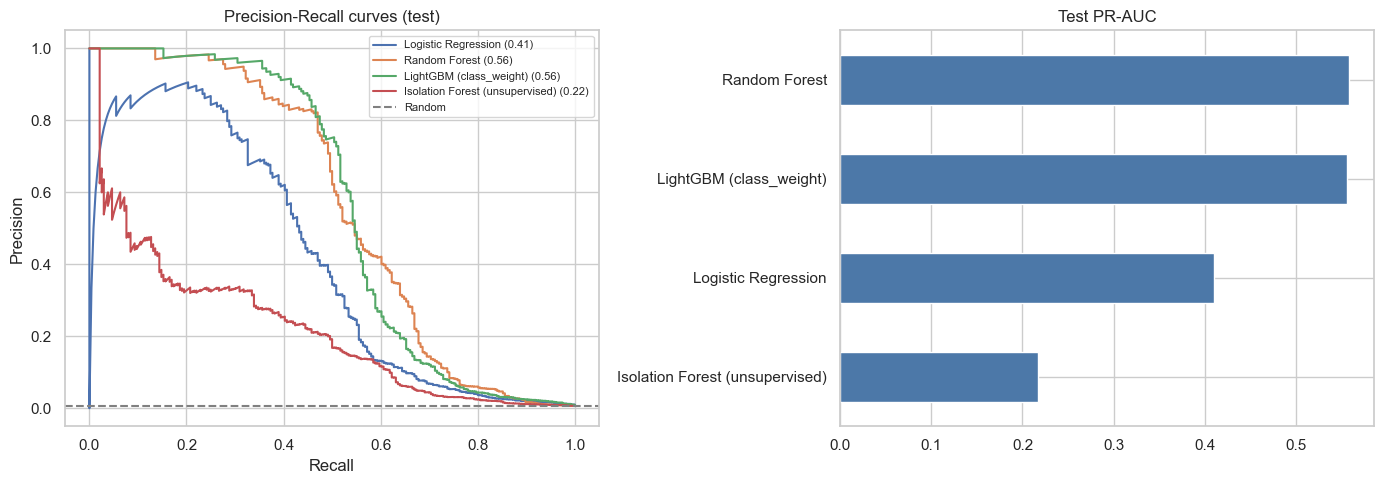

In [73]:
final_lgbm = strategies[best_strategy]

lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, max_depth=14,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1)

lr.fit(Xtr, ytr); rf.fit(Xtr, ytr); iso.fit(Xtr)          # Isolation Forest never sees labels

test_scores = {
    "Logistic Regression": lr.predict_proba(Xte)[:, 1],
    "Random Forest":       rf.predict_proba(Xte)[:, 1],
    f"LightGBM ({best_strategy})": final_lgbm.predict_proba(Xte)[:, 1],
    "Isolation Forest (unsupervised)": -iso.decision_function(Xte),
}
res = pd.DataFrame({k: evaluate(yte, s) for k, s in test_scores.items()}).T.sort_values("PR_AUC", ascending=False)
print(f"Test fraud rate (random-classifier PR-AUC) = {yte.mean():.4f}")
display(res.style.format("{:.3f}").highlight_max(color="#c7e9c0"))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, s in test_scores.items():
    p, r, _ = precision_recall_curve(yte, s); ax[0].plot(r, p, label=f"{name} ({average_precision_score(yte, s):.2f})")
ax[0].axhline(yte.mean(), ls="--", c="grey", label="Random"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Precision-Recall curves (test)"); ax[0].legend(fontsize=8)
res.PR_AUC.sort_values().plot.barh(ax=ax[1], color="#4C78A8"); ax[1].set_title("Test PR-AUC")
plt.tight_layout(); plt.show()

Random Forest is the best model with 0.557 PR AUC with a close tie with LightGBM (class_weight) but ROC AUC and Recall@80 are higher for LightGBM. Overall, do to the simplicity as well, LightGBM class imbalance with class weight seems to be the best choice.

## 7. Cost-sensitive threshold optimisation

F1 treats every error equally, but fraud errors are not equal:

- **Missed fraud (false negative)** costs the **transaction amount**
- **False alarm (false positive)** costs a flat **$5** (analyst review + customer friction)

I scan thresholds on the **validation** set, pick the one that minimises total dollar cost, then apply it
unchanged to the **test** set and compare it with the default 0.5 threshold and the F1-optimal threshold.

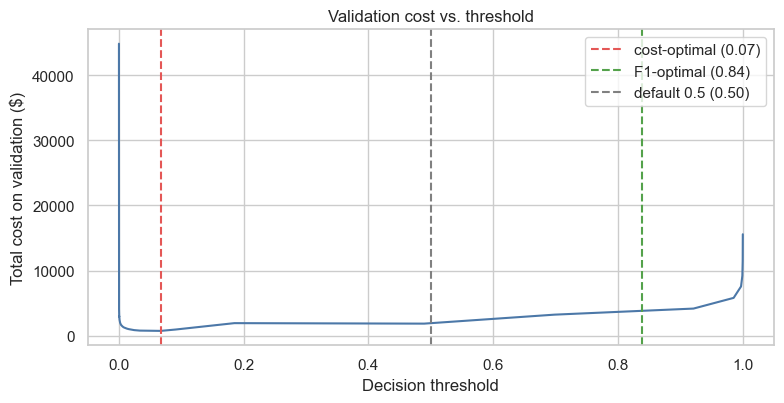

,threshold,alerts,frauds_caught,frauds_missed,false_alarms,fraud_loss,review_cost,total_cost,savings_vs_no_model,savings_%
No model (miss everything),nan,0,0,236,0,"$22,214",$0,"$22,214",$0,0.0%
Default threshold 0.5,0.500,162,120,116,42,"$9,601",$210,"$9,811","$12,403",55.8%
F1-optimal threshold,0.839,132,110,126,22,"$12,724",$110,"$12,834","$9,380",42.2%
Cost-optimal threshold,0.067,250,129,107,121,"$8,793",$605,"$9,398","$12,817",57.7%


In [75]:
FP_COST = 5.0 # False alarm cost
amt_va, amt_te = df.amount.values[val], df.amount.values[test] # amount values for validation and test sets, respectively.
s_va = final_lgbm.predict_proba(Xva)[:, 1] # prediction score of validation set. i.e. probabilities
s_te = final_lgbm.predict_proba(Xte)[:, 1] # prediction score of test set. i.e. probabilities

"""
For a given threshold, if the prediction probability is over the threshold, we flag the transaction as an alert for fraud.
fn - false negative (missed fraud) if we do not alert fraud but it is actually fraud.
fp - false positive (false alarm) if we alert fraud but it is not actually fraud.
tp - true positive (correctly identified fraud) if the transaction is alerted as fraud and is actually fraud.
"""
def confusion_cost(y_true, score, amount, thr):
    flag = score >= thr
    fn, fp, tp = (~flag) & (y_true == 1), flag & (y_true == 0), flag & (y_true == 1)
    return dict(threshold=thr, alerts=int(flag.sum()), frauds_caught=int(tp.sum()), frauds_missed=int(fn.sum()),
                false_alarms=int(fp.sum()), fraud_loss=amount[fn].sum(), review_cost=FP_COST * fp.sum(),
                total_cost=amount[fn].sum() + FP_COST * fp.sum())

grid = np.unique(np.quantile(s_va, np.linspace(0.50, 0.9999, 600)))
val_costs = np.array([confusion_cost(yva, s_va, amt_va, t)["total_cost"] for t in grid])
thr_cost = grid[val_costs.argmin()]

# Precision = TP / (TP + FP): of the alerts raised, the fraction that were real fraud.
# Recall = TP / (TP + FN): of all real frauds, the fraction you caught.
# thr_pr (the thresholds).
prec, rec, thr_pr = precision_recall_curve(yva, s_va)
# F1 is the harmonic mean of precision (P) and recall (R):
# F1 = 2PR / (P + R)
# [:-1] drops that extra appended point so the arrays line up one-to-one with thr_pr.
# 1e-12 is a tiny number added to the denominator to avoid dividing by zero when both P and R are 0.
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
# pick the best threshold
thr_f1 = thr_pr[f1.argmax()]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(grid, val_costs, c="#4C78A8"); ax.set_xlabel("Decision threshold"); ax.set_ylabel("Total cost on validation ($)")
for t, lab, c in [(thr_cost, "cost-optimal", "#E45756"), (thr_f1, "F1-optimal", "#54A24B"), (0.5, "default 0.5", "grey")]:
    ax.axvline(t, ls="--", c=c, label=f"{lab} ({t:.2f})")
ax.set_title("Validation cost vs. threshold"); ax.legend(); plt.tight_layout(); plt.show()

no_model_cost = amt_te[yte == 1].sum()
rows = {"No model (miss everything)": dict(threshold=np.nan, alerts=0, frauds_caught=0, frauds_missed=int(yte.sum()),
                                           false_alarms=0, fraud_loss=no_model_cost, review_cost=0.0, total_cost=no_model_cost)}
for lab, t in [("Default threshold 0.5", 0.5), ("F1-optimal threshold", thr_f1), ("Cost-optimal threshold", thr_cost)]:
    rows[lab] = confusion_cost(yte, s_te, amt_te, t)
cost_tbl = pd.DataFrame(rows).T
cost_tbl["savings_vs_no_model"] = no_model_cost - cost_tbl.total_cost
cost_tbl["savings_%"] = cost_tbl.savings_vs_no_model / no_model_cost * 100
display(cost_tbl.style.format({"threshold": "{:.3f}", "fraud_loss": "${:,.0f}", "review_cost": "${:,.0f}",
                               "total_cost": "${:,.0f}", "savings_vs_no_model": "${:,.0f}", "savings_%": "{:.1f}%",
                               "alerts": "{:,.0f}", "frauds_caught": "{:,.0f}", "frauds_missed": "{:,.0f}",
                               "false_alarms": "{:,.0f}"}))

The validation cost curve is nearly flat between thresholds of about 0.05 and  about 0.9, so the model is robust to the exact
cutoff and the "optimal" threshold (0.07) should not be over-interpreted. On the test set it performs the same as
the default 0.5 (57.7\% vs. 55.8\% cost reduction). The F1-optimal threshold is clearly worse (42.2\%), because F1
weights a miss of 19 frauds but 99 fewer alarms. The takeaway is to optimise the metric
that matches the business cost, not necessarily to tune the threshold finely.

## 8. Concept drift: how fast does the model decay?

After day 70 the fraudsters change tactics (**pattern D: low-and-slow local purchases**), which look very
different from the patterns the model was trained on. I compare, week by week through the test period:

- **Static model**: trained once on days 0-44 and never updated
- **Weekly retrained model**: retrained at the start of each week on all history up to that date
  (assumes labels arrive without delay, a simplification discussed in the limitations)

,frauds,pattern_D_share,static_PR_AUC,retrained_PR_AUC
period,,,,
Days 60-66,57,0%,0.936,0.949
Days 67-73,72,60%,0.445,0.459
Days 74-80,54,65%,0.362,0.401
Days 81-89,53,53%,0.471,0.584


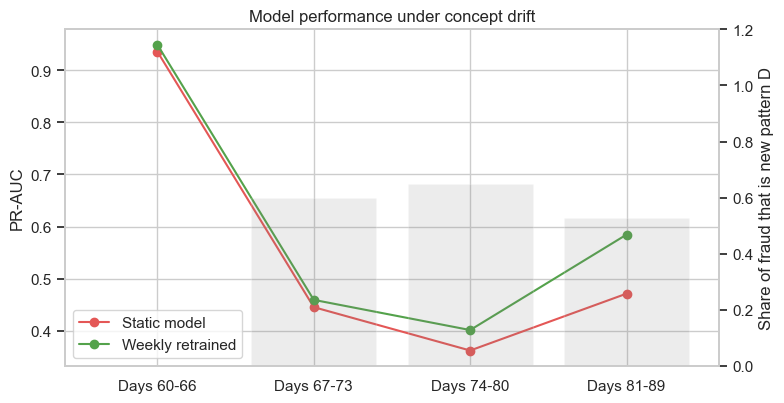

In [76]:
test_df = df[test].copy()
test_df["week"] = ((test_df.day - 60) // 7).clip(upper=3)
week_labels = {0: "Days 60-66", 1: "Days 67-73", 2: "Days 74-80", 3: "Days 81-89"}

static_model = strategies["class_weight"]       # same recipe, trained once
rows = []
for w in range(4):
    wk_start = 60 + 7 * w
    m_wk = (test_df.week == w).values
    Xw, yw = Xte[m_wk], yte[m_wk]
    hist = (df.day < wk_start).values
    retrained = make_lgbm(scale_pos_weight=(y[hist] == 0).sum() / (y[hist] == 1).sum()).fit(X[hist], y[hist])
    share_d = (test_df.loc[m_wk, "fraud_type"] == "D_low_and_slow").sum() / max(yw.sum(), 1)
    rows.append({"period": week_labels[w], "frauds": int(yw.sum()), "pattern_D_share": share_d,
                 "static_PR_AUC": average_precision_score(yw, static_model.predict_proba(Xw)[:, 1]),
                 "retrained_PR_AUC": average_precision_score(yw, retrained.predict_proba(Xw)[:, 1])})
drift = pd.DataFrame(rows).set_index("period")
display(drift.style.format({"pattern_D_share": "{:.0%}", "static_PR_AUC": "{:.3f}", "retrained_PR_AUC": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(drift.index, drift.static_PR_AUC, "o-", c="#E45756", label="Static model")
ax.plot(drift.index, drift.retrained_PR_AUC, "o-", c="#54A24B", label="Weekly retrained")
ax2 = ax.twinx(); ax2.bar(drift.index, drift.pattern_D_share, alpha=.15, color="grey"); ax2.set_ylabel("Share of fraud that is new pattern D"); ax2.set_ylim(0, 1.2); ax2.grid(False)
ax.set_ylabel("PR-AUC"); ax.set_title("Model performance under concept drift"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

We can see the static model does poorly with the more pattern D in the test set. Makes sense as the static model never was trained on such fraud. The weekly updated model performs better than static as the number of weeks see increases as more data is used to train the new model as opposed to the static model is stuck not being able to identify pattern D as fraud.

## 9. Explainability with SHAP

Banks must be able to justify why a transaction was flagged (analyst workflow, customer disputes,
regulation). SHAP assigns each feature a contribution to each individual prediction. First the global view,
then **per-alert reason codes** in plain English.

How to read it\
Each dot is one transaction from the test sample.
Horizontal position is the SHAP value: how much that feature pushed that transaction’s score. Right means toward fraud, left means toward legitimate, and 0 means no effect.
Colour is the feature’s value: red is high, blue is low.
Rows are sorted by overall importance, the average absolute SHAP value, so `log_amount` matters most.
The units are log-odds. A SHAP of +2 multiplies the odds of fraud by about e² ≈ 7, and +8 by about 3,000. The scale is distorted by the class weighting, so don’t read the scores as true probabilities. The relative pattern is still valid.

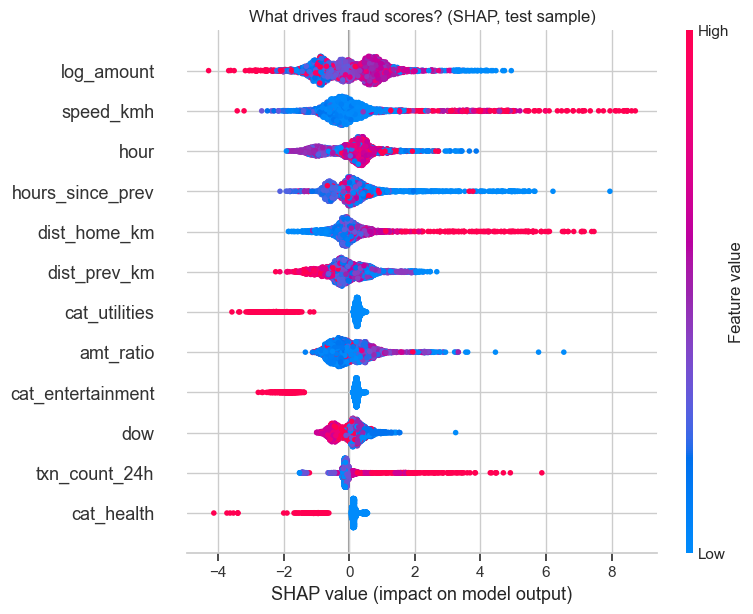

In [77]:
explainer = shap.TreeExplainer(final_lgbm)

def shap_matrix(Xdf):
    sv = explainer.shap_values(Xdf)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

# global view on a sample of the test set (all frauds + random legit rows)
rng = np.random.default_rng(SEED)
te_idx = np.where(test)[0]
sample = np.concatenate([te_idx[yte == 1], rng.choice(te_idx[yte == 0], 3000, replace=False)])
sv_global = shap_matrix(X.iloc[sample])
shap.summary_plot(sv_global, X.iloc[sample], max_display=12, show=False)
plt.title("What drives fraud scores? (SHAP, test sample)"); plt.tight_layout(); plt.show()

SHAP shows that the model relies mainly on a few variables. Low values of `log_amount`, `cat_utilities`, `cat_entertainment` `cat_health` push more to be legitimate as generally fraud agents want to spend large amounts, and won't spend on health, entertainment, or health. High values
of V4 push the fraud score up, with `speed_kmh` the dominant driver (SHAP up to about +8 log-odds for a subset of frauds).
`speed_kmh`, `dist_home_km`, and `txt_count_24f` contribute largely to being fraud as higher speeds, larger distance from home transactions and number of transactions in a 24 hour period are huge indicators for fraud. Caveats: the sample over-represents
fraud, so the ranking reflects behaviour on fraudulent rows.

ALERT  customer 1413 | $57.55 at 'restaurant' | 2025-03-05 03:39 | risk score 1.00 | actual: FRAUD
   - implied travel speed of 156 km/h since previous purchase  (SHAP +6.82)
   - 675 km from the customer's usual location  (SHAP +4.46)
   - 4.3 h since previous transaction  (SHAP +2.54) 

ALERT  customer 872 | $65.02 at 'restaurant' | 2025-03-29 01:44 | risk score 1.00 | actual: FRAUD
   - 5 other transactions in the past hour  (SHAP +5.94)
   - implied travel speed of 38 km/h since previous purchase  (SHAP +4.18)
   - purchase at 01:44  (SHAP +2.98) 

ALERT  customer 1353 | $114.25 at 'retail' | 2025-03-03 18:04 | risk score 0.99 | actual: FRAUD
   - implied travel speed of 209 km/h since previous purchase  (SHAP +7.95)
   - 951 km from the customer's usual location  (SHAP +4.14)
   - 4.5 h since previous transaction  (SHAP +2.54) 

ALERT  customer 937 | $40.16 at 'grocery' | 2025-03-06 20:41 | risk score 1.00 | actual: FRAUD
   - implied travel speed of 1,571 km/h since previous purc

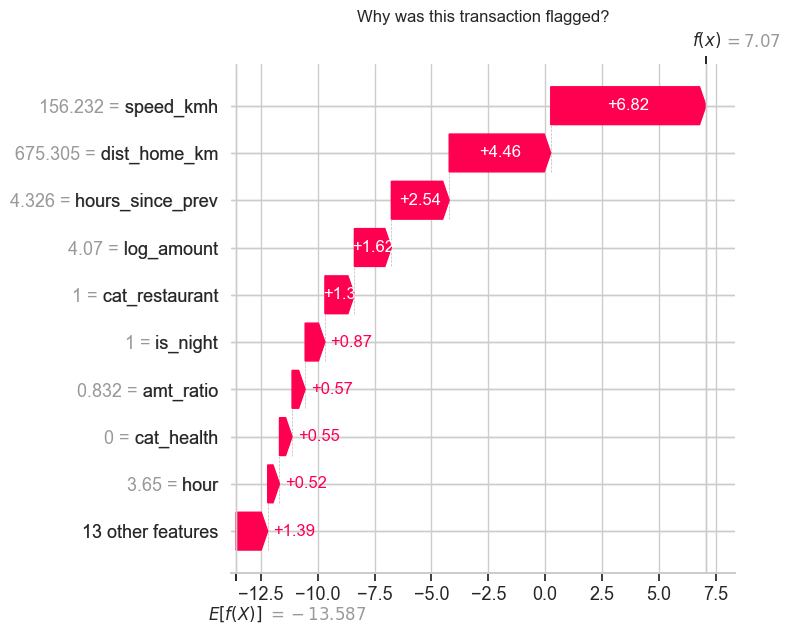

In [78]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
TEMPLATES = {
    "speed_kmh":        lambda v: f"implied travel speed of {v:,.0f} km/h since previous purchase",
    "dist_prev_km":     lambda v: f"{v:,.0f} km from previous purchase",
    "dist_home_km":     lambda v: f"{v:,.0f} km from the customer's usual location",
    "amt_ratio":        lambda v: f"amount is {v:.1f}x the customer's recent average",
    "log_amount":       lambda v: f"transaction amount of ${np.expm1(v):,.2f}",
    "txn_count_1h":     lambda v: f"{int(v)} other transactions in the past hour",
    "txn_count_24h":    lambda v: f"{int(v)} other transactions in the past 24 hours",
    "hours_since_prev": lambda v: f"only {v * 60:.0f} min since previous transaction" if v < 2 else f"{v:.1f} h since previous transaction",
    "hour":             lambda v: f"purchase at {int(v):02d}:{int((v % 1) * 60):02d}",
    "is_night":         lambda v: "overnight purchase" if v else "daytime purchase",
    "dow":              lambda v: f"purchase on a {DOW[int(v)]}",
    "new_category":     lambda v: "first purchase in this merchant category" if v else "familiar merchant category",
}
def reason(feat, val):
    if feat.startswith("cat_"): return f"merchant category: {feat[4:]}"
    return TEMPLATES[feat](val) if feat in TEMPLATES else f"{feat} = {val:.2f}"

def alert_card(row_pos, k=3):
    row = X.iloc[[row_pos]]
    sv = shap_matrix(row)[0]
    top = [i for i in np.argsort(-sv)[:k] if sv[i] > 0]
    r = df.iloc[row_pos]
    head = (f"ALERT  customer {r.customer_id} | ${r.amount:,.2f} at '{r.category}' | {r.ts:%Y-%m-%d %H:%M} | "
            f"risk score {final_lgbm.predict_proba(row)[0, 1]:.2f} | actual: {'FRAUD' if r.is_fraud else 'legit'}")
    return head + "\n" + "\n".join(f"   - {reason(X.columns[i], row.iloc[0, i])}  (SHAP {sv[i]:+.2f})" for i in top)

flagged = np.where(test)[0][s_te >= thr_cost]
caught = flagged[df.is_fraud.values[flagged] == 1]
false_pos = flagged[df.is_fraud.values[flagged] == 0]
rng = np.random.default_rng(7)
demo = list(rng.choice(caught, 4, replace=False)) + list(rng.choice(false_pos, 1, replace=False))
for p in demo:
    print(alert_card(p), "\n")

# waterfall for first caught fraud from demo.
if len(demo):
    row = X.iloc[[demo[0]]]
    base = float(np.ravel(explainer.expected_value)[-1])
    shap.plots.waterfall(shap.Explanation(values=shap_matrix(row)[0], base_values=base,
                                          data=row.iloc[0].values, feature_names=list(X.columns)),
                         max_display=10, show=False)
    plt.title("Why was this transaction flagged?"); plt.tight_layout(); plt.show()

## How to read the waterfall

The first alert in the list (the $57.55 fraud), drawn as a running total in log-odds.

- **Start at the bottom.** `E[f(X)] = -13.587` is the model's average raw output across the data. It's very negative because most transactions are clearly legitimate. It is the average of the raw scores, not the log-odds of the 0.7% fraud rate, so don't read it as a base rate.
- **Each bar is one feature's push.** `speed_kmh` = 156.23 adds **+6.82**, dist_home_km adds +4.46, hours_since_prev adds +2.54, and so on. The 13 remaining features add +1.39 together.
- **The top is the final score.** -13.587 + 6.82 + 4.46 + ... + 1.39 ≈ **7.07**. As a probability that's 1/(1+e⁻7.09) ≈ 99.9%, which matches the "risk score 1.00" on the card.
- **The numbers on the left** are this transaction's actual feature values. Every bar is red, so nothing pushed the score down here.

This is SHAP's main strength: the contributions add up exactly to the score, so the explanation is faithful to the model.

Per-alert SHAP shows why each transaction was flagged. The contributions sum exactly to the model's log-odds score
(e.g. -13.585 baseline + 20.65 total push = 7.07, or ~99.9% fraud probability). In all four correctly flagged frauds,
a high implied travel speed contributes +4.18 to +8.35 log-odds, with distance from the customer's usual location, hours since previous transaction and number of transactions in the past hour adding smaller confirming pushes. The effect of
high implied travel speed saturates below about -4, as expected from threshold-based tree splits. The one false positive in the sample
has 70.12 dollars transaction amount, overnight purchase, 4 transactions in the past 24 hours and weaker supporting evidence (score 0.55 vs. ~1.00 for the frauds), so kind of
borderline alert that appears to not really be a fraud. These explanations identify
what drives the model, not the real-world cause of fraud.

## 10. Business impact summary

In [79]:
best = cost_tbl.loc["Cost-optimal threshold"]
n_days_test = N_DAYS - 60
total_fraud_usd = no_model_cost
caught_usd = amt_te[(s_te >= thr_cost) & (yte == 1)].sum()

display(Markdown(f'''
**Test period ({n_days_test} days, {len(yte):,} transactions, {int(yte.sum())} fraudulent):**

- Fraud dollars at risk with no model: **\${total_fraud_usd:,.0f}**
- Fraud dollars stopped by the model at the cost-optimal threshold: **\${caught_usd:,.0f}** ({caught_usd / total_fraud_usd:.0%})
- Frauds caught: **{int(best.frauds_caught)} of {int(yte.sum())}** ({best.frauds_caught / yte.sum():.0%} recall)
- Alerts raised: **{int(best.alerts)}** (~{best.alerts / n_days_test:.1f} per day), of which {int(best.false_alarms)} were false alarms
- Net cost reduction vs. no model (after paying \${FP_COST:.0f} per false alarm): **\${best.savings_vs_no_model:,.0f}** ({best["savings_%"]:.0f}\%)
'''))


**Test period (30 days, 36,423 transactions, 236 fraudulent):**

- Fraud dollars at risk with no model: **\$22,214**
- Fraud dollars stopped by the model at the cost-optimal threshold: **\$13,422** (60%)
- Frauds caught: **129 of 236** (55% recall)
- Alerts raised: **250** (~8.3 per day), of which 121 were false alarms
- Net cost reduction vs. no model (after paying \$5 per false alarm): **\$12,817** (58\%)


## 11. Limitations and next steps

**Limitations**
- **Synthetic data.** Fraud patterns are ones synthetically defined, so absolute scores overstate real-world performance.
  What transfers is the *methodology*: leakage-free features, time-based validation, cost-based thresholds, drift monitoring.
- **Label delay.** In production, fraud labels (chargebacks) arrive days or weeks late. The retraining experiment
  assumes instant labels; a realistic version would train only on labels available at retraining time.
- **Fixed costs.** A flat $5 review cost and "loss = amount" ignore chargeback fees, recovery rates and customer lifetime value.
- **Threshold stability.** The threshold was tuned on pre-drift validation data; under drift it would need re-tuning.
- **No real-time constraints.** Feature computation here is batch; a deployed system needs a feature store and sub-100 ms scoring.

**Furture test**
- Swap in a real dataset (*Sparkov*, *IEEE-CIS*) and compare.